# Rossman dataset 

Fuente xgboost: https://xgboost.readthedocs.io/en/release_3.0.0/

Correr esto:

https://www.kaggle.com/competitions/rossmann-store-sales/data

- Id - an Id that represents a (Store, Date) duple within the test set
- Store - a unique Id for each store
- Sales - the turnover for any given day (this is what you are predicting)
- Customers - the number of customers on a given day
- Open - an indicator for whether the store was open: 0 = closed, 1 = open
- StateHoliday - indicates a state holiday. Normally all stores, with few exceptions, are closed on state holidays. Note that all schools are closed on public holidays and weekends. a = public holiday, b = Easter holiday, c = Christmas, 0 = None
- SchoolHoliday - indicates if the (Store, Date) was affected by the closure of public schools
- StoreType - differentiates between 4 different store models: a, b, c, d
- Assortment - describes an assortment level: a = basic, b = extra, c = extended
- CompetitionDistance - distance in meters to the nearest competitor store
- CompetitionOpenSince[Month/Year] - gives the approximate year and month of the time the nearest competitor was opened
- Promo - indicates whether a store is running a promo on that day
- Promo2 - Promo2 is a continuing and consecutive promotion for some stores: 0 = store is not participating, 1 = store is participating
- Promo2Since[Year/Week] - describes the year and calendar week when the store started participating in Promo2
- PromoInterval - describes the consecutive intervals Promo2 is started, naming the months the promotion is started anew. E.g. "Feb,May,Aug,Nov" means each round starts in February, May, August, November of any given year for that store

In [4]:
import xgboost, sklearn
print("XGBoost:", xgboost.__version__)
print("scikit-learn:", sklearn.__version__)


XGBoost: 3.1.1
scikit-learn: 1.7.2


### Tuneando xgboost

- n_estimators: número total de árboles a entrenar. Si usas early_stopping_rounds, puedes poner un número alto sin preocuparte por overfitting.

- max_depth: profundidad máxima de cada árbol. Profundidades mayores capturan más complejidad, pero pueden sobreajustar.

- learning_rate: qué tan rápido aprende el modelo. Valores más bajos requieren más árboles (n_estimators más alto), pero suelen generalizar mejor.

- tree_method: método para construir árboles:

    'exact': busca el mejor split evaluando todos los valores.
    
    'hist': agrupa en bins (default moderno), mucho más rápido.
    
    'gpu_hist': como 'hist' pero usando GPU (⚡ si tienes una buena GPU).

- subsample: fracción de los datos usados en cada árbol (filas). Ayuda a reducir overfitting. Ej: 0.8 usa el 80% de los datos en cada iteración.

- colsample_bytree (¡ojo con el nombre!): fracción de columnas seleccionadas aleatoriamente para cada árbol. También ayuda contra el overfitting.

- early_stopping_rounds: si la métrica en el conjunto de validación no mejora durante N iteraciones, se detiene el entrenamiento (requiere eval_set).

- eval_metric: métrica usada para evaluar el desempeño durante entrenamiento (ej. 'rmse', 'mae', 'logloss', 'auc'). Es la que define si se activa early_stopping.

- gamma: mínima ganancia necesaria para hacer un split adicional. Ayuda a regular complejidad.

- reg_lambda: regularización L2 (Ridge). Útil para evitar sobreajuste.

- reg_alpha: regularización L1 (Lasso). Puede hacer pruning de features.



# Instala xgboost

```
!pip install xgboost
```

In [5]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor, plot_tree, plot_importance
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

# ----------------------------
# CARGA Y PREPROCESAMIENTO
# ----------------------------
train = pd.read_csv('rossman.csv')
stores = pd.read_csv('store.csv')

df = pd.merge(train, stores, on='Store')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')
df = df[df['Open'] == 1]

# FEATURES temporales sencillos
df['month'] = df['Date'].dt.month
df['day_of_month'] = df['Date'].dt.day
df['week_of_year'] = df['Date'].dt.isocalendar().week.astype(int)

# Limpiar columnas no usadas
df = df.drop(columns=['Date', 'Store', 'Customers', 'Open'])

target = 'Sales'

# ----------------------------
# SPLIT TEMPORAL: train / valid / test = 70/20/10
# ----------------------------
n = len(df)
i_train = int(n * 0.70)
i_valid = int(n * 0.90)

train_df = df.iloc[:i_train]
valid_df = df.iloc[i_train:i_valid]
test_df  = df.iloc[i_valid:]

X_train = pd.get_dummies(train_df.drop(columns=target), drop_first=True)
y_train = train_df[target]
X_valid = pd.get_dummies(valid_df.drop(columns=target), drop_first=True)
y_valid = valid_df[target]
X_test  = pd.get_dummies(test_df.drop(columns=target),  drop_first=True)
y_test  = test_df[target]

# Alinear columnas
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)
X_test  = X_test.reindex(columns=X_train.columns,  fill_value=0)


/var/folders/q7/z6bgw1fj4vng6rs97g1chhz00000gn/T/ipykernel_20255/3473161985.py:10: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv('rossman.csv')


## Entrena un xgboost

In [6]:
# Entrenamiento
model = XGBRegressor(
    n_estimators=4000,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    random_state=42,
    early_stopping_rounds=100
)


# Importante: proveer eval_set; sklearn API usará automáticamente best_iteration
model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train),(X_valid, y_valid)],
    verbose=50 
)

# Predicción: en sklearn API ya usa best_iteration internamente en 3.1.1
y_pred = model.predict(X_test)

r2   = r2_score(y_test, y_pred)
print(f"R² (test): {r2:.4f}")

[0]	validation_0-rmse:2979.82009	validation_1-rmse:3138.28891
[50]	validation_0-rmse:2100.22255	validation_1-rmse:2261.10558
[100]	validation_0-rmse:1764.40134	validation_1-rmse:1964.12418
[150]	validation_0-rmse:1558.49672	validation_1-rmse:1790.09406
[200]	validation_0-rmse:1395.41895	validation_1-rmse:1707.58999
[250]	validation_0-rmse:1297.59491	validation_1-rmse:1630.54097
[300]	validation_0-rmse:1205.32357	validation_1-rmse:1556.68216
[350]	validation_0-rmse:1138.25482	validation_1-rmse:1507.37531
[400]	validation_0-rmse:1094.94924	validation_1-rmse:1493.62735
[450]	validation_0-rmse:1055.99945	validation_1-rmse:1465.41101
[500]	validation_0-rmse:1026.00177	validation_1-rmse:1453.31833
[550]	validation_0-rmse:999.11800	validation_1-rmse:1438.13244
[600]	validation_0-rmse:972.07433	validation_1-rmse:1425.07677
[650]	validation_0-rmse:949.88207	validation_1-rmse:1415.31850
[700]	validation_0-rmse:932.04025	validation_1-rmse:1421.54933
[742]	validation_0-rmse:920.18717	validation_1-

## Grafica el primer arbol

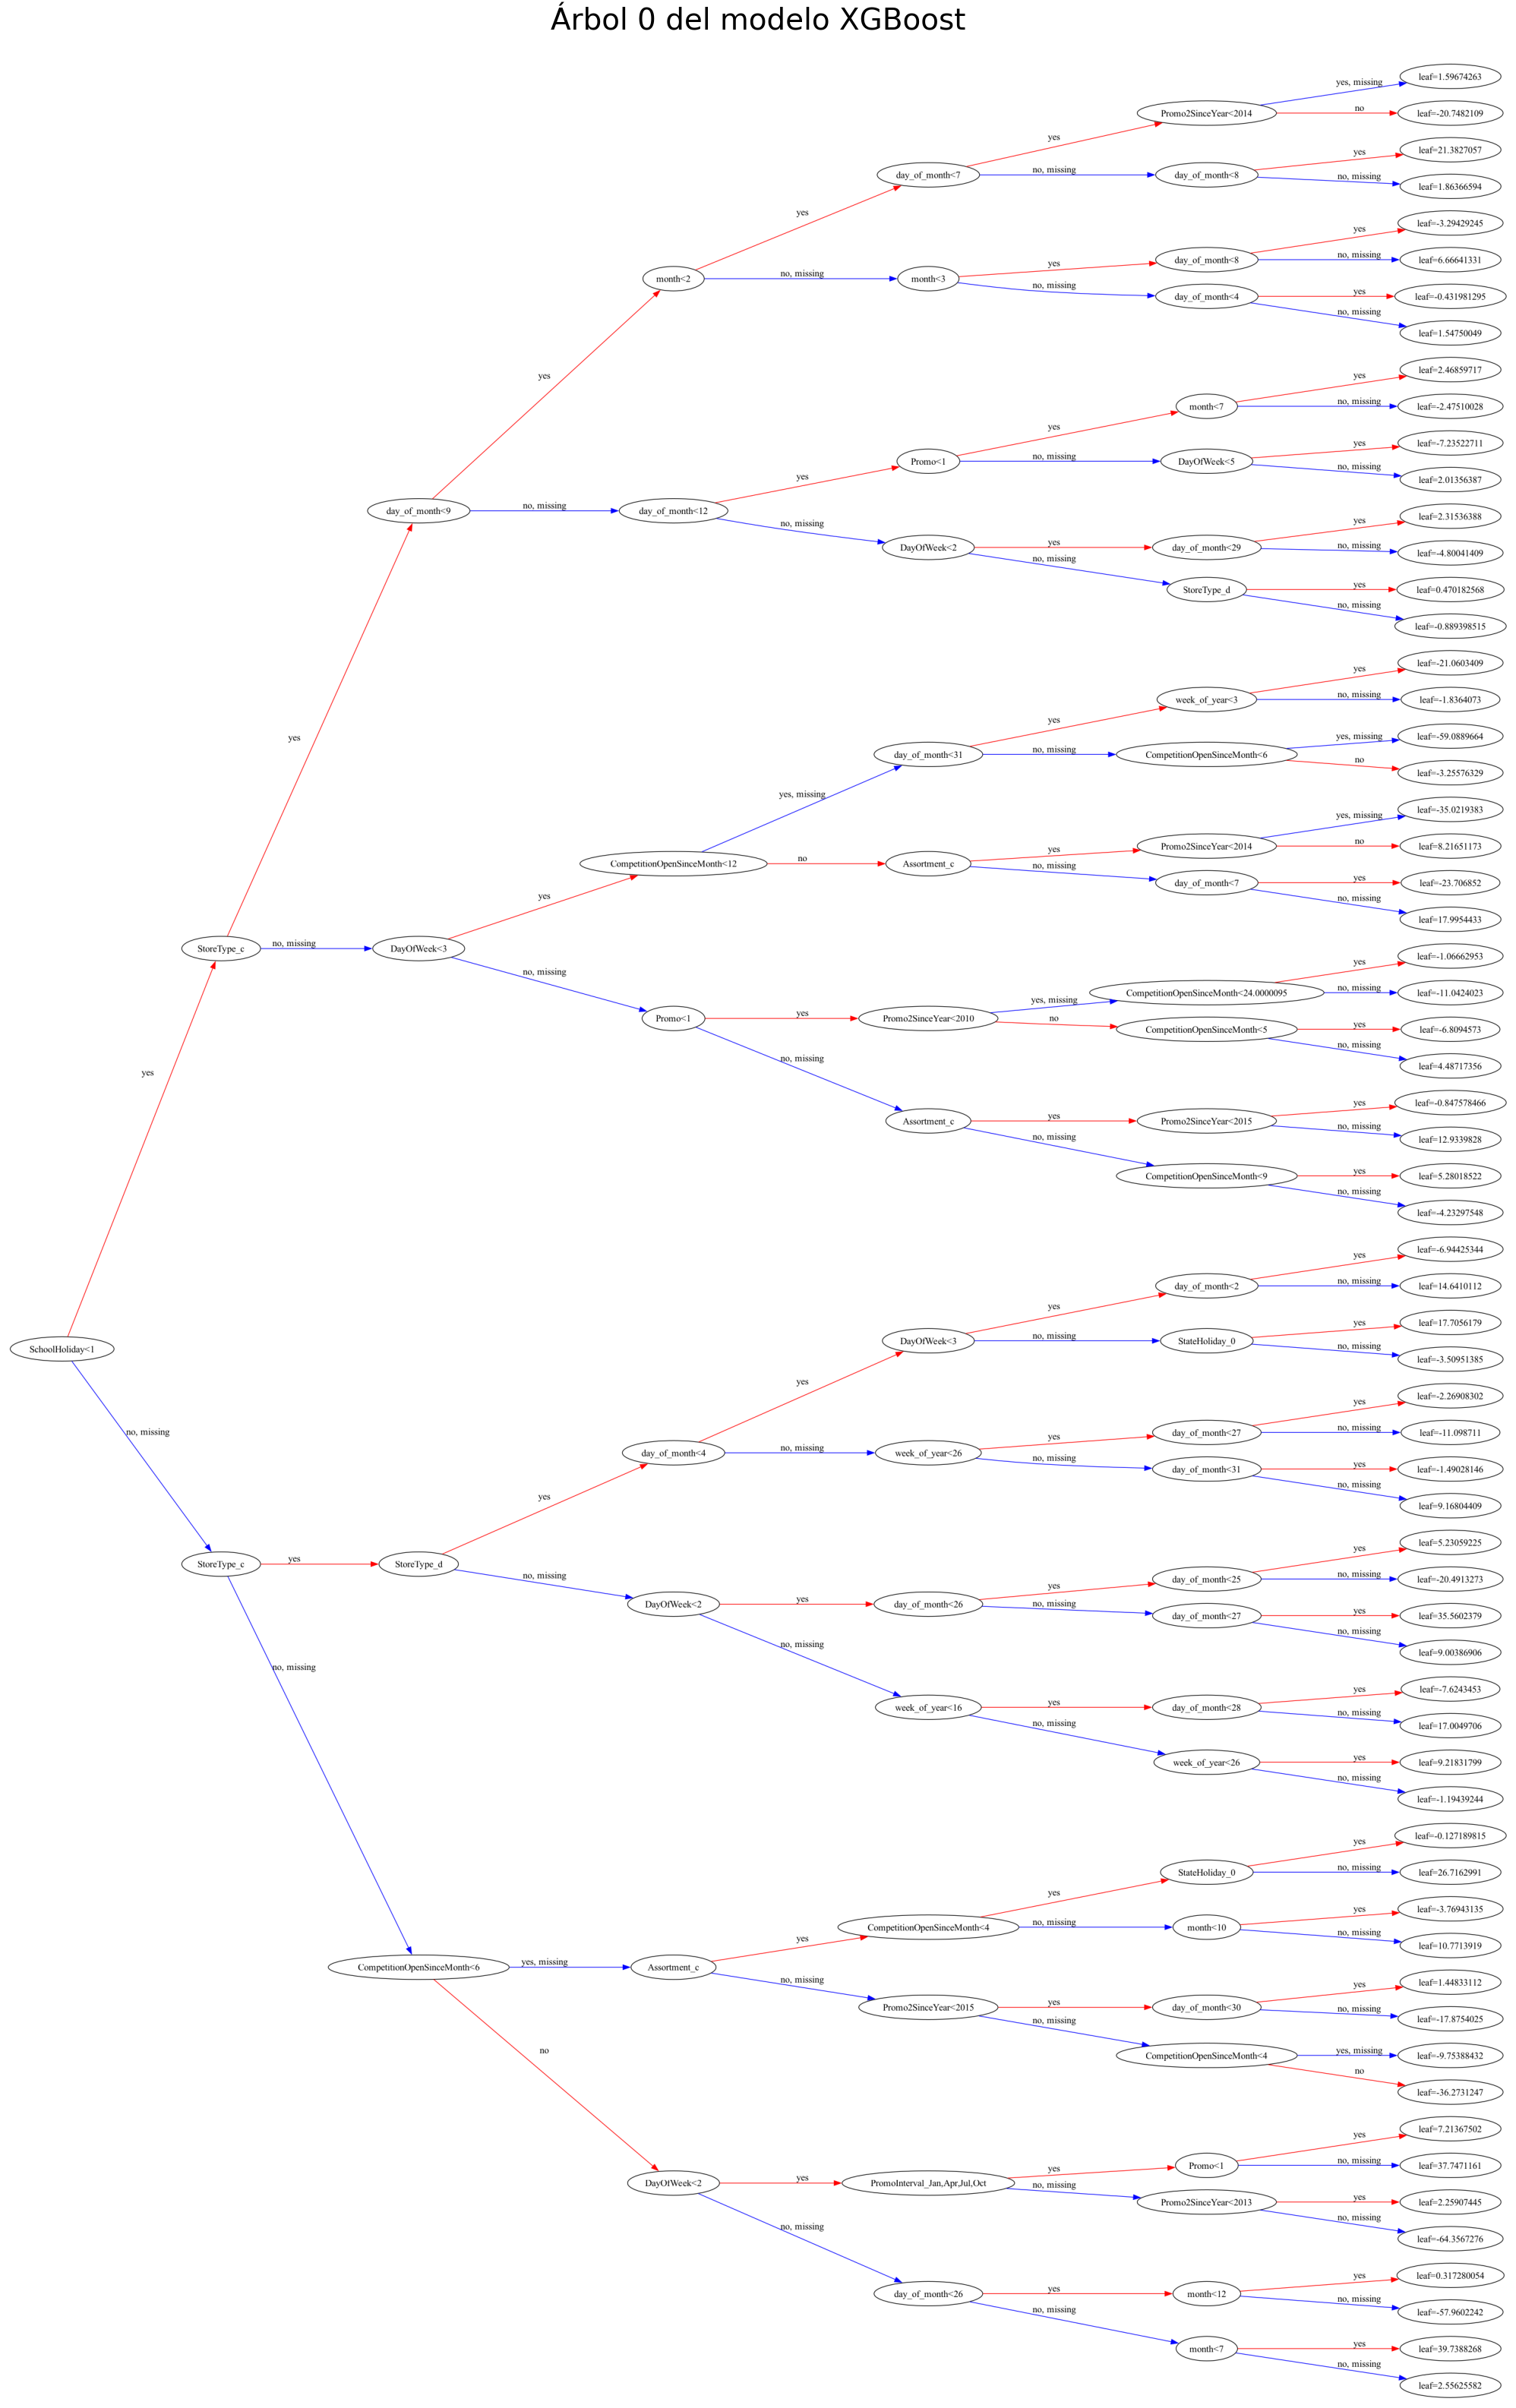

In [7]:
# Dibuja el primer árbol del modelo
fig, ax = plt.subplots(figsize=(80, 40))  # más grande
plot_tree(
    model,
    tree_idx=740,        
    rankdir='LR',      
    ax=ax,
    fmap='',
)
plt.title("Árbol 0 del modelo XGBoost", fontsize=28, pad=30)
plt.rcParams['font.size'] = 16
plt.show()

# Gráficando las funciones de perdida

In [8]:
results = model.evals_result_

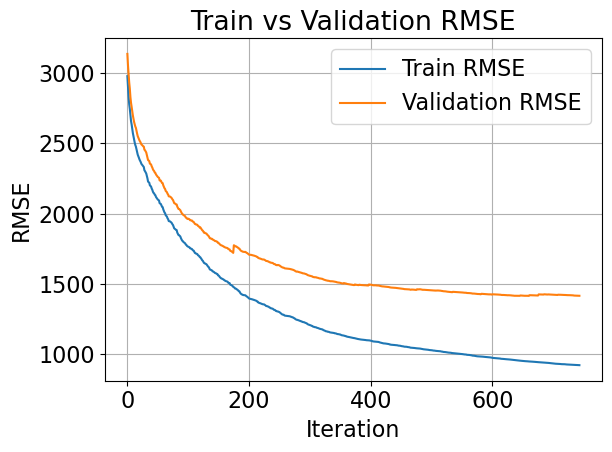

In [9]:
plt.plot(results['validation_0']['rmse'], label='Train RMSE')
plt.plot(results['validation_1']['rmse'], label='Validation RMSE')
plt.xlabel('Iteration')
plt.ylabel('RMSE')

plt.title('Train vs Validation RMSE')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Comparando con una regresión lineal

In [11]:
from sklearn.linear_model import LinearRegression

# Calcular medias solo en train
mean_impute = X_train.mean()

# Aplicar a ambos
X_train_filled = X_train.fillna(mean_impute)
X_test_filled = X_test.fillna(mean_impute)  # usar media del train, no del test

# Entrenar modelo
lm = LinearRegression().fit(X_train_filled, y_train)

# Predecir
predictions_lm = lm.predict(X_test_filled)

# Evaluar
r2 = r2_score(y_test, predictions_lm)
print(f"R² regresión lineal (con media): {r2:.4f}")


R² regresión lineal (con media): 0.1985


# Funciones de perdida

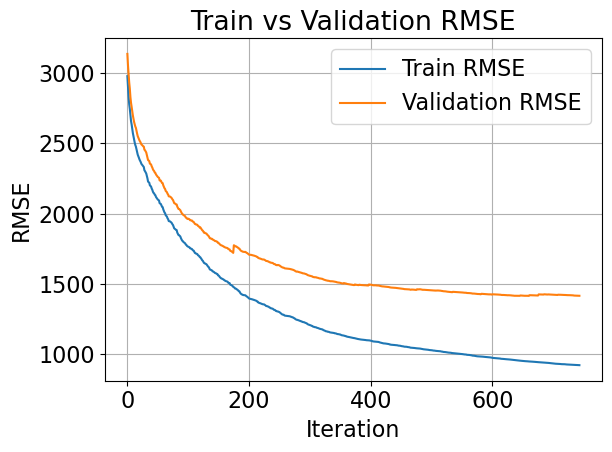

In [12]:
results = model.evals_result()

plt.plot(results['validation_0']['rmse'], label='Train RMSE')
plt.plot(results['validation_1']['rmse'], label='Validation RMSE')
plt.xlabel('Iteration')
plt.ylabel('RMSE')

plt.title('Train vs Validation RMSE')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Ordenamiento

In [13]:
ordenamiento = pd.DataFrame({
    'y_val': y_test,
    'preds_xgboost': y_pred,
    'preds_lm': predictions_lm
})

ordenamiento['bins'] = pd.qcut(ordenamiento['y_val'], q=10, labels=False) + 1
ordenamiento['bins'] = pd.qcut(ordenamiento['y_val'], q=10, labels=False) + 1

group_ordenamiento = ordenamiento.groupby('bins').mean()


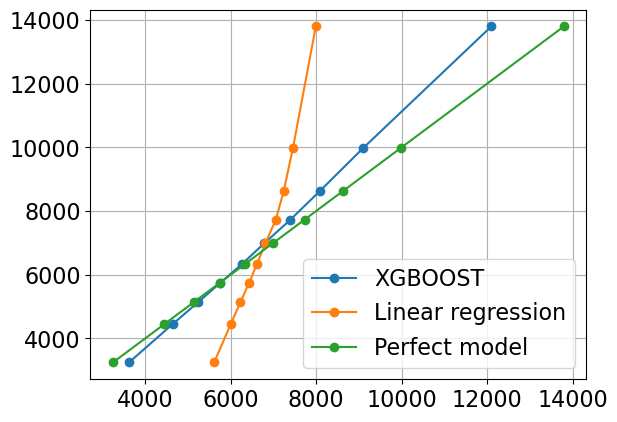

In [14]:
plt.plot(group_ordenamiento['preds_xgboost'], group_ordenamiento['y_val'], marker="o", label="XGBOOST")
plt.plot(group_ordenamiento['preds_lm'], group_ordenamiento['y_val'], marker="o", label="Linear regression")
plt.plot(group_ordenamiento['y_val'], group_ordenamiento['y_val'], marker="o", label="Perfect model")
plt.legend()
plt.grid()

### Feature importances 

# Feature importance

### Gain 
Gain es que tanto disminuye la función de perdida, en promedio al usar cada feature


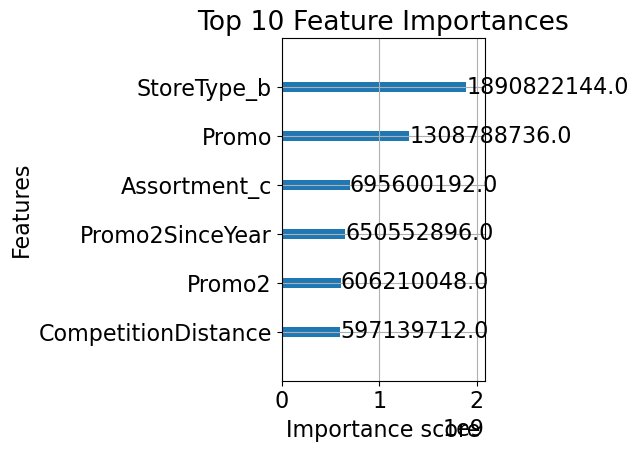

In [19]:
from xgboost import plot_importance

plot_importance(model, max_num_features=6, importance_type='gain')
plt.title("Top 10 Feature Importances")
plt.tight_layout()
plt.show()


### Weight
Weighr es el porcentaje de veces que se uso esa variable

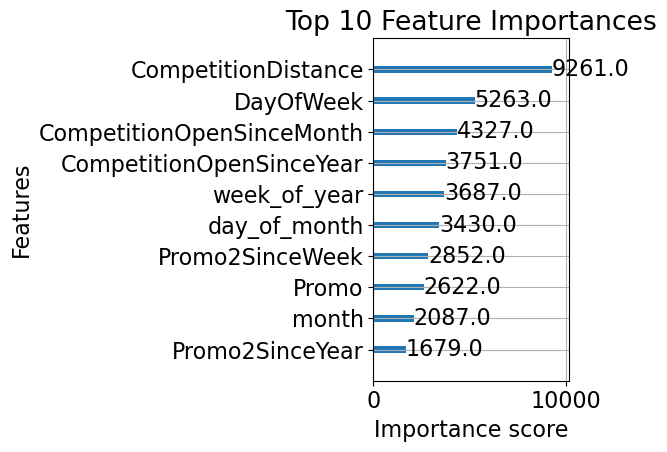

In [20]:
plot_importance(model, max_num_features=10, importance_type='weight')
plt.title("Top 10 Feature Importances")
plt.tight_layout()
plt.show()